# Промежуточная защита: прогноз энергопотребления на 15 минут

**Задача:** регрессия. После получения измерения `Usage_kWh` за текущий интервал
прогнозируем энергию за **один следующий 15-минутный интервал**. Один объект -
момент выдачи прогноза, его история и фактическое потребление следующего интервала.
Единица измерения - **кВт·ч (энергия), а не кВт (мощность)**.

На тесте модель остаётся фиксированной, но после каждого интервала получает новое
измерение. Это последовательный прогноз на один шаг, не прогноз всего квартала
из одной начальной точки. При задержке показаний схема потребует изменения.

**Основная модель использует только историю потребления и известный календарь.**
Доступность текущих CO₂, реактивных измерений и `Load_Type` в реальном времени
датасет не подтверждает. Их связь с потреблением исследована, а расширение модели
такими показателями проверяется отдельно и не определяет основного победителя.


## Вклад участников

Роли ниже перенесены из исходного ноутбука; это заявленное авторами распределение работы.

| Участник | Роль | Вклад в исходный проект |
|---|---|---|
| Булатов Алий | Team Lead | Постановка задачи, координация, итоговые выводы |
| Русаков Евгений | Team Lead | Планирование, методология валидации, ревью кода |
| Ишмуллин Рифат | Data Analyst | Первичный анализ, качество и распределения данных |
| Лопаткин Артём | Data Analyst | Взаимосвязи, нагрузка и дни недели |
| Андреев Дмитрий | Data Analyst | Альтернативный вариант решения и сравнение подходов |
| Маракин Захар | ML | Основной вариант, признаки, модели и оптимизация |

В исправленной версии добавлены проверки времени, доступности признаков,
раздельные периоды настройки и выбора модели, сезонные baseline, абляция,
переобучение на полном train и более осторожные выводы.

## Этап 1. Загрузка и первичный анализ данных
### Шаг 1. Библиотеки и настройки

`pandas` и `numpy` обрабатывают данные, `matplotlib` и `seaborn` строят графики,
`scikit-learn` задаёт пайплайны, метрики и поиск параметров, CatBoost обучает бустинг,
Optuna направляет поиск параметров с учётом предыдущих попыток.

In [71]:
pip install catboost optuna

In [72]:
from pathlib import Path
import hashlib
import importlib.metadata as metadata
import json
import os
import platform

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from IPython.display import display, Markdown
from sklearn.base import clone
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler, MinMaxScaler, OneHotEncoder
from sklearn.linear_model import LinearRegression
from sklearn.ensemble import RandomForestRegressor
from sklearn.model_selection import TimeSeriesSplit, RandomizedSearchCV, cross_validate
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
from catboost import CatBoostRegressor
import optuna

SEED = 42
THREADS = min(4, os.cpu_count() or 1)
N_SPLITS = 3
RF_SEARCH_ITER = 8
OPTUNA_TRIALS = 12
TEST_START = pd.Timestamp('2018-10-20 00:00:00')
STEP = pd.Timedelta(minutes=15)
np.random.seed(SEED)
optuna.logging.set_verbosity(optuna.logging.WARNING)
sns.set_theme(style='whitegrid', font='DejaVu Sans')
plt.rcParams.update({'figure.figsize': (11, 4.5), 'figure.dpi': 110})
pd.set_option('display.max_columns', 30)
pd.set_option('display.max_rows', 40)

def conclusion(text):
    display(Markdown('Вывод:  ' + text))

versions = {p: metadata.version(p) for p in
            ['numpy', 'pandas', 'scipy', 'scikit-learn', 'catboost', 'optuna',
             'matplotlib', 'seaborn', 'ipython']}
print('Python:', platform.python_version(), '| Потоков:', THREADS)
display(pd.Series(versions, name='Версия').to_frame())


Python: 3.13.18 | Потоков: 2


,Версия
numpy,2.4.6
pandas,2.2.3
scipy,1.16.3
scikit-learn,1.6.1
catboost,1.2.10
optuna,5.1.0
matplotlib,3.10.0
seaborn,0.13.2
ipython,7.34.0


### Шаг 2. Загрузка исходных данных

In [73]:
DATA_PATH = Path('Steel_industry_data.csv')
if not DATA_PATH.is_file():
    raise FileNotFoundError('Положите Steel_industry_data.csv из архива рядом с ноутбуком.')
data_sha256 = hashlib.sha256(DATA_PATH.read_bytes()).hexdigest()
expected_sha256 = '9b1cee6f9cb9cd9df2b95814ca90a9a2ff15b7f5f1fba0fae3c643e82072eacc'
assert data_sha256 == expected_sha256, 'CSV изменился: перед повторением выводов проверьте новый набор.'
raw = pd.read_csv(DATA_PATH)
display(raw.head())
print('SHA-256:', data_sha256)
conclusion('Загружен тот же исходный CSV, что использовался в проверке. '
           'Контрольная сумма защищает от незаметной подмены данных.')

,date,Usage_kWh,Lagging_Current_Reactive.Power_kVarh,Leading_Current_Reactive_Power_kVarh,CO2(tCO2),Lagging_Current_Power_Factor,Leading_Current_Power_Factor,NSM,WeekStatus,Day_of_week,Load_Type
0,01/01/2018 00:15,3.17,2.95,0.0,0.0,73.21,100.0,900,Weekday,Monday,Light_Load
1,01/01/2018 00:30,4.00,4.46,0.0,0.0,66.77,100.0,1800,Weekday,Monday,Light_Load
2,01/01/2018 00:45,3.24,3.28,0.0,0.0,70.28,100.0,2700,Weekday,Monday,Light_Load
3,01/01/2018 01:00,3.31,3.56,0.0,0.0,68.09,100.0,3600,Weekday,Monday,Light_Load
4,01/01/2018 01:15,3.82,4.50,0.0,0.0,64.72,100.0,4500,Weekday,Monday,Light_Load


SHA-256: 9b1cee6f9cb9cd9df2b95814ca90a9a2ff15b7f5f1fba0fae3c643e82072eacc


Вывод:  Загружен тот же исходный CSV, что использовался в проверке. Контрольная сумма защищает от незаметной подмены данных.

### Шаг 3. Структура данных

In [74]:
print('Размер:', raw.shape)
raw.info()
display(raw.dtypes.astype(str).rename('Тип').to_frame())
conclusion(f'В наборе {len(raw):,} строк и {raw.shape[1]} столбцов. '
           'Дата пока записана текстом, электрические измерения - числа, '
           'день недели и тип нагрузки - категории. Число строк равно 365 × 96, '
           'но полноту временной сетки отдельно проверим после преобразования дат.')

Размер: (35040, 11)
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 35040 entries, 0 to 35039
Data columns (total 11 columns):
 #   Column                                Non-Null Count  Dtype  
---  ------                                --------------  -----  
 0   date                                  35040 non-null  object 
 1   Usage_kWh                             35040 non-null  float64
 2   Lagging_Current_Reactive.Power_kVarh  35040 non-null  float64
 3   Leading_Current_Reactive_Power_kVarh  35040 non-null  float64
 4   CO2(tCO2)                             35040 non-null  float64
 5   Lagging_Current_Power_Factor          35040 non-null  float64
 6   Leading_Current_Power_Factor          35040 non-null  float64
 7   NSM                                   35040 non-null  int64  
 8   WeekStatus                            35040 non-null  object 
 9   Day_of_week                           35040 non-null  object 
 10  Load_Type                             35040 non-null  object 


,Тип
date,object
Usage_kWh,float64
Lagging_Current_Reactive.Power_kVarh,float64
Leading_Current_Reactive_Power_kVarh,float64
CO2(tCO2),float64
Lagging_Current_Power_Factor,float64
Leading_Current_Power_Factor,float64
NSM,int64
WeekStatus,object
Day_of_week,object


Вывод:  В наборе 35,040 строк и 11 столбцов. Дата пока записана текстом, электрические измерения - числа, день недели и тип нагрузки - категории. Число строк равно 365 × 96, но полноту временной сетки отдельно проверим после преобразования дат.

### Шаг 4. Пропуски, полные дубликаты и допустимые диапазоны

In [75]:
display(raw.isna().sum().rename('Пропуски').to_frame())
print('Полных дубликатов:', raw.duplicated().sum())
assert raw.isna().sum().sum() == 0
assert raw.duplicated().sum() == 0
measure_cols = raw.select_dtypes(include='number').columns.tolist()
assert (raw[measure_cols] >= 0).all().all()
pf_cols = ['Lagging_Current_Power_Factor', 'Leading_Current_Power_Factor']
assert raw[pf_cols].le(100).all().all()
zero_rows = raw.loc[raw['Usage_kWh'].eq(0)]
display(zero_rows)
conclusion('Пропусков и полных дубликатов нет. Все проверенные измерения '
           'неотрицательны, коэффициенты мощности находятся в диапазоне 0-100. '
           f'Нулевое потребление встречается {len(zero_rows)} раз.')

,Пропуски
date,0
Usage_kWh,0
Lagging_Current_Reactive.Power_kVarh,0
Leading_Current_Reactive_Power_kVarh,0
CO2(tCO2),0
Lagging_Current_Power_Factor,0
Leading_Current_Power_Factor,0
NSM,0
WeekStatus,0
Day_of_week,0


Полных дубликатов: 0


,date,Usage_kWh,Lagging_Current_Reactive.Power_kVarh,Leading_Current_Reactive_Power_kVarh,CO2(tCO2),Lagging_Current_Power_Factor,Leading_Current_Power_Factor,NSM,WeekStatus,Day_of_week,Load_Type
29855,07/11/2018 00:00,0.0,0.0,0.0,0.0,0.0,0.0,0,Weekday,Wednesday,Light_Load


Вывод:  Пропусков и полных дубликатов нет. Все проверенные измерения неотрицательны, коэффициенты мощности находятся в диапазоне 0-100. Нулевое потребление встречается 1 раз.

### Шаг 5. Описательная статистика

Граница теста задана заранее. Для решений о моделировании исследуем только более ранний
перио, общие проверки целостности файла выше не используются для выбора модели.

In [76]:
parsed_dates = pd.to_datetime(raw['date'], format='%d/%m/%Y %H:%M', errors='raise')
eda = raw.loc[parsed_dates < TEST_START].copy()
eda['date'] = parsed_dates.loc[eda.index]
eda = eda.sort_values('date').reset_index(drop=True)
display(eda.describe().round(3))
u = eda['Usage_kWh']
conclusion(f'До начала теста среднее потребление равно {u.mean():.2f} кВт·ч, '
           f'медиана - {u.median():.2f}, максимум - {u.max():.2f}. '
           'Среднее заметно выше медианы: периоды большой нагрузки поднимают '
           'средний уровень. Одного среднего недостаточно, чтобы описать типичный интервал.')

,date,Usage_kWh,Lagging_Current_Reactive.Power_kVarh,Leading_Current_Reactive_Power_kVarh,CO2(tCO2),Lagging_Current_Power_Factor,Leading_Current_Power_Factor,NSM
count,28032,28032.000,28032.000,28032.000,28032.000,28032.000,28032.000,28032.000
mean,2018-05-26 23:52:30,27.926,13.257,3.860,0.012,79.947,84.540,42750.000
min,2018-01-01 00:00:00,2.450,0.000,0.000,0.000,36.940,12.500,0.000
25%,2018-03-14 23:56:15,3.130,2.740,0.000,0.000,61.640,99.820,21375.000
50%,2018-05-26 23:52:30,4.610,5.040,0.000,0.000,87.980,100.000,42750.000
75%,2018-08-07 23:48:45,51.260,22.900,2.090,0.020,99.070,100.000,64125.000
max,2018-10-19 23:45:00,153.140,96.910,27.760,0.070,100.000,100.000,85500.000
std,NaN,33.921,16.486,7.481,0.016,19.388,30.378,24940.623


Вывод:  До начала теста среднее потребление равно 27.93 кВт·ч, медиана - 4.61, максимум - 153.14. Среднее заметно выше медианы: периоды большой нагрузки поднимают средний уровень. Одного среднего недостаточно, чтобы описать типичный интервал.

### Шаг 6. Даты, сортировка и непрерывность времени

In [77]:
backward_steps = int(parsed_dates.diff().lt(pd.Timedelta(0)).sum())
df_raw = raw.copy()
df_raw['date'] = parsed_dates
df_raw = df_raw.sort_values('date').reset_index(drop=True)
assert not df_raw['date'].duplicated().any()
assert df_raw['date'].diff().dropna().eq(STEP).all()
assert df_raw['date'].iloc[0] == pd.Timestamp('2018-01-01 00:00')
assert df_raw['date'].iloc[-1] == pd.Timestamp('2018-12-31 23:45')
expected_nsm = df_raw['date'].dt.hour * 3600 + df_raw['date'].dt.minute * 60
assert expected_nsm.eq(df_raw['NSM']).all()
assert df_raw['date'].dt.day_name().eq(df_raw['Day_of_week']).all()
assert df_raw['date'].dt.dayofweek.ge(5).eq(df_raw['WeekStatus'].eq('Weekend')).all()
print('Обратных переходов в исходном порядке:', backward_steps)
print('Период:', df_raw['date'].min(), '-', df_raw['date'].max())
print('Все интервалы после сортировки равны 15 минутам, календарные поля согласованы.')
display(df_raw[['date', 'Usage_kWh', 'NSM']].head())
conclusion('В исходном файле полночь каждого дня стоит после 23:45 этого же дня, '
           'поэтому исходный порядок строк нельзя использовать для лагов. После '
           'сортировки получен полный год без временных разрывов и повторных дат.')

Обратных переходов в исходном порядке: 365
Период: 2018-01-01 00:00:00 - 2018-12-31 23:45:00
Все интервалы после сортировки равны 15 минутам, календарные поля согласованы.


,date,Usage_kWh,NSM
0,2018-01-01 00:00:00,3.42,0
1,2018-01-01 00:15:00,3.17,900
2,2018-01-01 00:30:00,4.00,1800
3,2018-01-01 00:45:00,3.24,2700
4,2018-01-01 01:00:00,3.31,3600


Вывод:  В исходном файле полночь каждого дня стоит после 23:45 этого же дня, поэтому исходный порядок строк нельзя использовать для лагов. После сортировки получен полный год без временных разрывов и повторных дат.

### Шаг 7. Распределение потребления

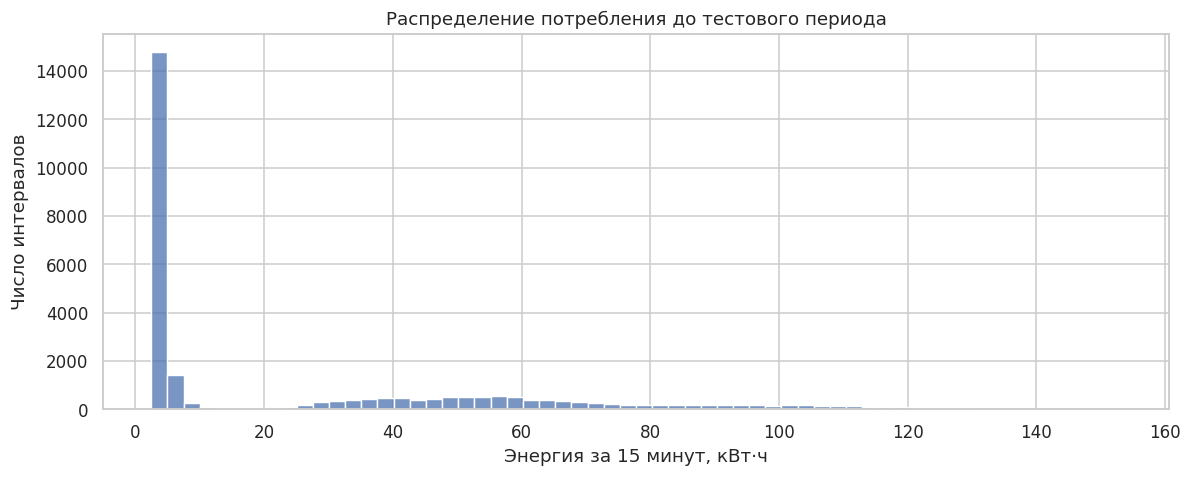

Вывод:  Малые значения встречаются часто, а большие образуют правый хвост. MAE показывает среднюю величину промаха в понятных единицах, а RMSE дополнительно выделяет крупные ошибки. Пики важны для бизнеса, поэтому не исключаем их из оценки и рассматриваем обе метрики.

In [78]:
fig, ax = plt.subplots()
sns.histplot(eda['Usage_kWh'], bins=60, ax=ax)
ax.set(title='Распределение потребления до тестового периода',
       xlabel='Энергия за 15 минут, кВт·ч', ylabel='Число интервалов')
plt.tight_layout(); plt.show()
conclusion('Малые значения встречаются часто, а большие образуют правый хвост. '
           'MAE показывает среднюю величину промаха в понятных единицах, '
           'а RMSE дополнительно выделяет крупные ошибки. Пики важны для бизнеса, '
           'поэтому не исключаем их из оценки и рассматриваем обе метрики.')

### Шаг 8. Потребление во времени и повторяющиеся режимы

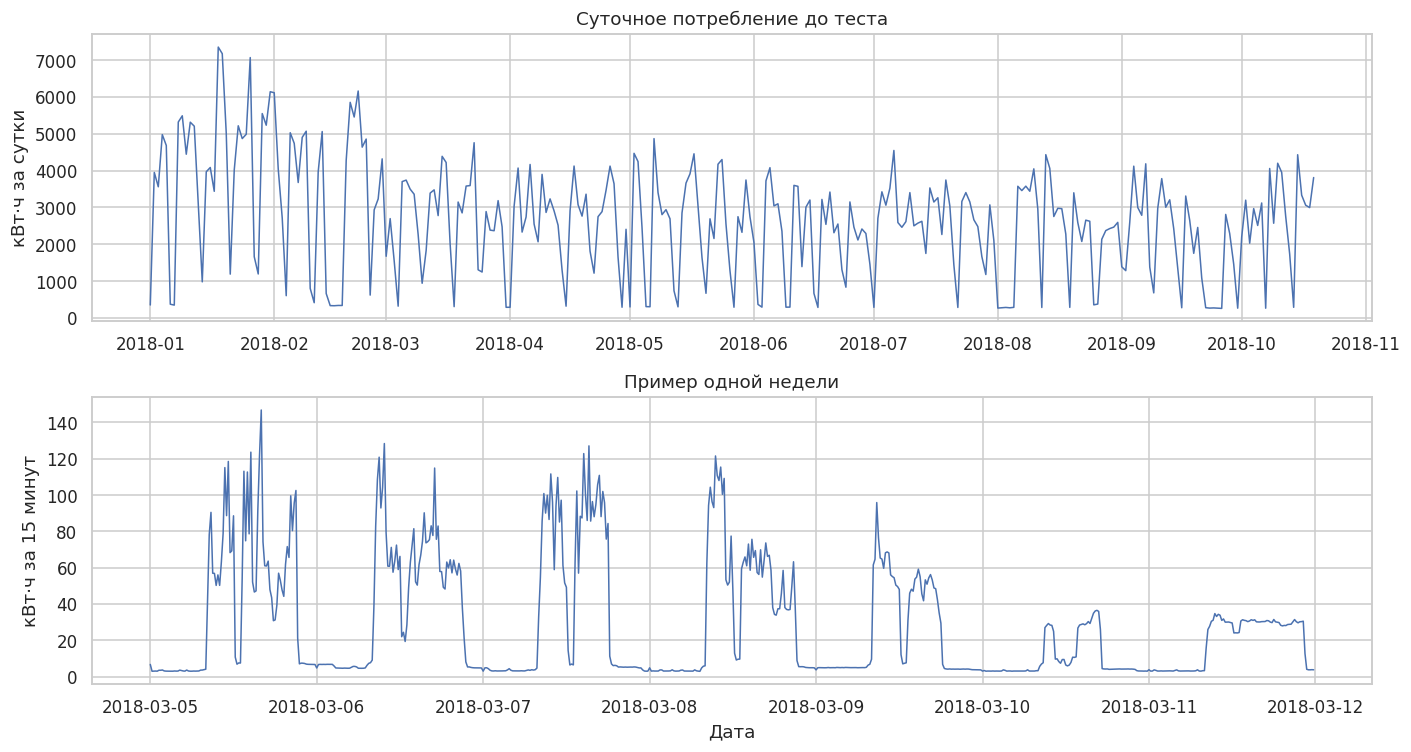

,Автокорреляция
1 интервалов,0.909
4 интервалов,0.687
96 интервалов,0.604
672 интервалов,0.668


Вывод:  Соседние измерения связаны между собой, суточные и недельные сдвиги тоже содержат информацию. Проверим прогноз по последнему значению, суткам и неделе. Эти наблюдения обосновывают временную валидацию, но сами по себе не доказывают стационарность или её отсутствие.

In [79]:
fig, axes = plt.subplots(2, 1, figsize=(13, 7))
daily = eda.set_index('date')['Usage_kWh'].resample('D').sum()
axes[0].plot(daily.index, daily.values, lw=1)
axes[0].set(title='Суточное потребление до теста', ylabel='кВт·ч за сутки')
week = eda.loc[eda['date'].between('2018-03-05', '2018-03-11 23:45')]
axes[1].plot(week['date'], week['Usage_kWh'], lw=1)
axes[1].set(title='Пример одной недели', ylabel='кВт·ч за 15 минут', xlabel='Дата')
plt.tight_layout(); plt.show()
autocorr = pd.Series({f'{lag} интервалов': eda['Usage_kWh'].autocorr(lag)
                     for lag in [1, 4, 96, 672]}, name='Автокорреляция')
display(autocorr.round(3).to_frame())
conclusion('Соседние измерения связаны между собой, суточные и недельные '
           'сдвиги тоже содержат информацию. Проверим прогноз по последнему значению, '
           'суткам и неделе. Эти наблюдения обосновывают временную валидацию, '
           'но сами по себе не доказывают стационарность или её отсутствие.')

### Шаг 8.1. Диапазоны и необычные значения

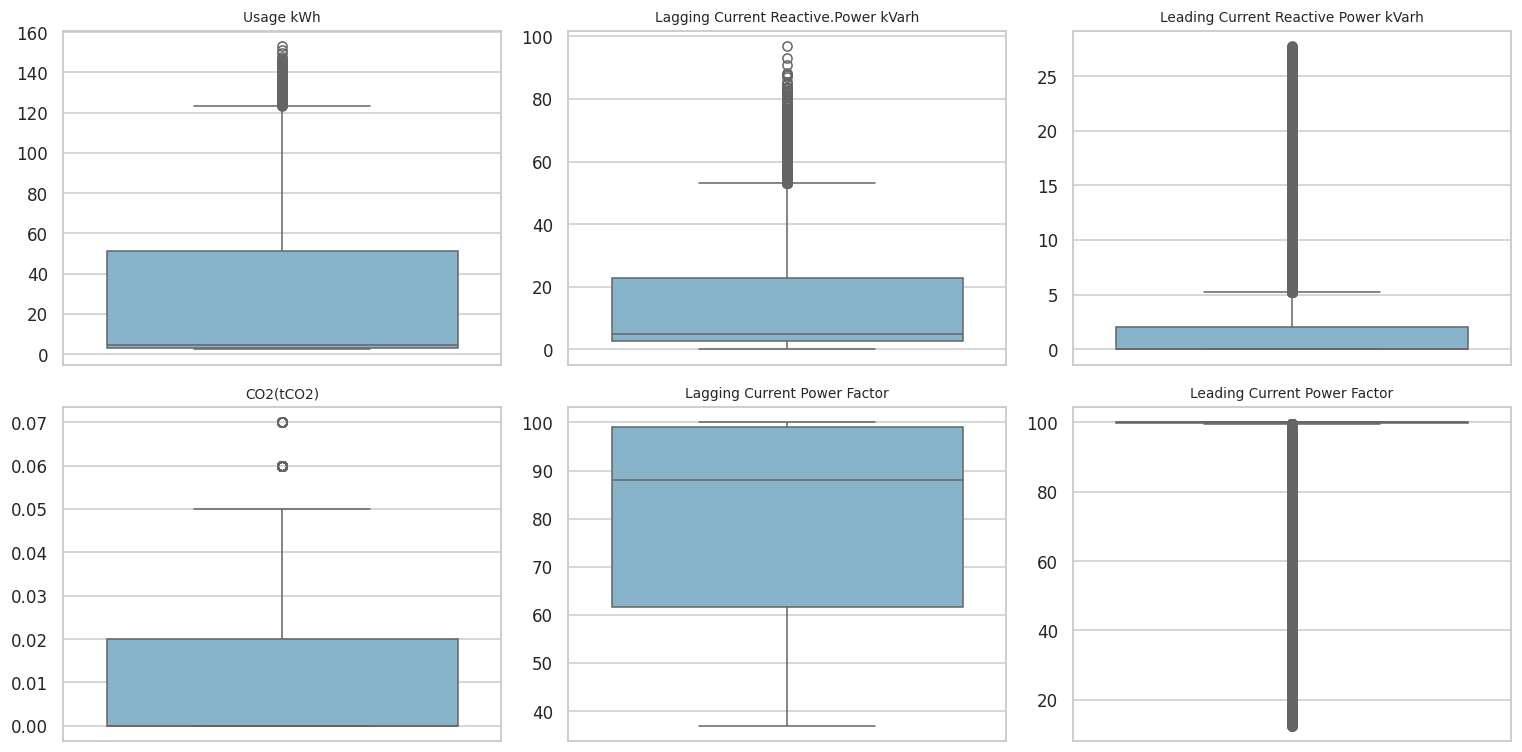

Вывод:  Значения за усами boxplot - необычные относительно основной массы наблюдений, но не обязательно ошибочные. Без производственного журнала оснований удалять их нет. Масштабы показателей различаются, для линейной модели сравним скейлеры, а деревьям масштабирование не требуется.

In [80]:
eda_numeric = ['Usage_kWh', 'Lagging_Current_Reactive.Power_kVarh',
               'Leading_Current_Reactive_Power_kVarh', 'CO2(tCO2)',
               'Lagging_Current_Power_Factor', 'Leading_Current_Power_Factor']
fig, axes = plt.subplots(2, 3, figsize=(14, 7))
for ax, col in zip(axes.ravel(), eda_numeric):
    sns.boxplot(y=eda[col], ax=ax, color='#7cb6d6')
    ax.set_title(col.replace('_', ' '), fontsize=9)
    ax.set_ylabel('')
plt.tight_layout(); plt.show()
conclusion('Значения за усами boxplot - необычные относительно основной массы '
           'наблюдений, но не обязательно ошибочные. Без производственного журнала '
           'оснований удалять их нет. Масштабы показателей различаются, для линейной '
           'модели сравним скейлеры, а деревьям масштабирование не требуется.')

## Этап 2. Взаимосвязи
### Шаг 9. Корреляционная матрица

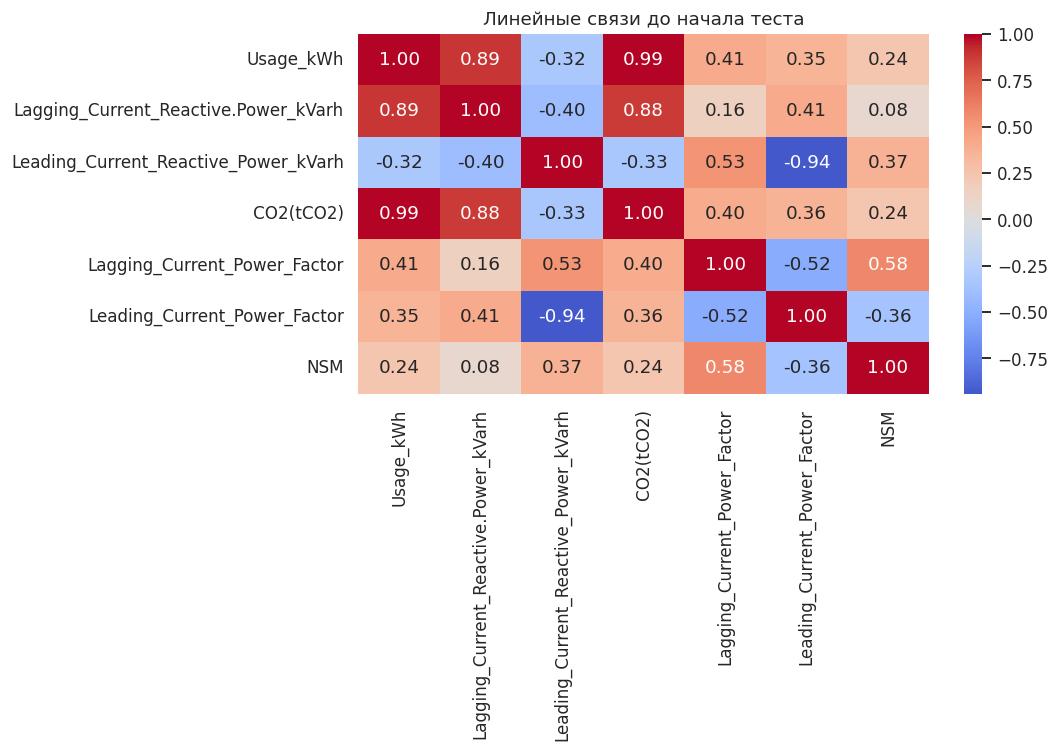

Вывод:  Некоторые показатели меняются вместе. Корреляция помогает заметить связь, но не доказывает, что один показатель вызывает другой или улучшит прогноз будущего интервала. Здесь измеряется связь с текущим потреблением.

In [81]:
corr_matrix = eda.select_dtypes(include='number').corr()
fig, ax = plt.subplots(figsize=(10, 7))
sns.heatmap(corr_matrix, annot=True, fmt='.2f', cmap='coolwarm', center=0, ax=ax)
ax.set_title('Линейные связи до начала теста')
plt.tight_layout(); plt.show()
conclusion('Некоторые показатели меняются вместе. Корреляция помогает заметить '
           'связь, но не доказывает, что один показатель вызывает другой или '
           'улучшит прогноз будущего интервала. Здесь измеряется связь с текущим потреблением.')

### Шаг 10. Связи с потреблением и доступность показателей

In [82]:
target_corr = corr_matrix['Usage_kWh'].drop('Usage_kWh').sort_values(ascending=False)
display(target_corr.round(4).rename('Корреляция с текущим Usage').to_frame())
pf_corr = float(target_corr['Lagging_Current_Power_Factor'])
conclusion(f'Связь Lagging_Current_Power_Factor с потреблением положительная '
           f'({pf_corr:.3f}), а не отрицательная. CO₂ и запаздывающая реактивная '
           'энергия тесно связаны с текущей нагрузкой, сила и знак связей других '
           'показателей различаются. Неизвестно, когда эти измерения '
           'поступают в систему. Поэтому основной прогноз опирается на измеренный '
           'Usage и календарь, расширенный набор рассмотрим как условный эксперимент.')

,Корреляция с текущим Usage
CO2(tCO2),0.9872
Lagging_Current_Reactive.Power_kVarh,0.8879
Lagging_Current_Power_Factor,0.4058
Leading_Current_Power_Factor,0.3542
NSM,0.2404
Leading_Current_Reactive_Power_kVarh,-0.3227


Вывод:  Связь Lagging_Current_Power_Factor с потреблением положительная (0.406), а не отрицательная. CO₂ и запаздывающая реактивная энергия тесно связаны с текущей нагрузкой, сила и знак связей других показателей различаются. Неизвестно, когда эти измерения поступают в систему. Поэтому основной прогноз опирается на измеренный Usage и календарь, расширенный набор рассмотрим как условный эксперимент.

### Шаг 11. Тип нагрузки

,count,mean,median,max
Load_Type,,,,
Light_Load,14368,8.91,3.20,140.29
Medium_Load,7808,36.99,31.21,153.14
Maximum_Load,5856,62.50,57.82,149.65


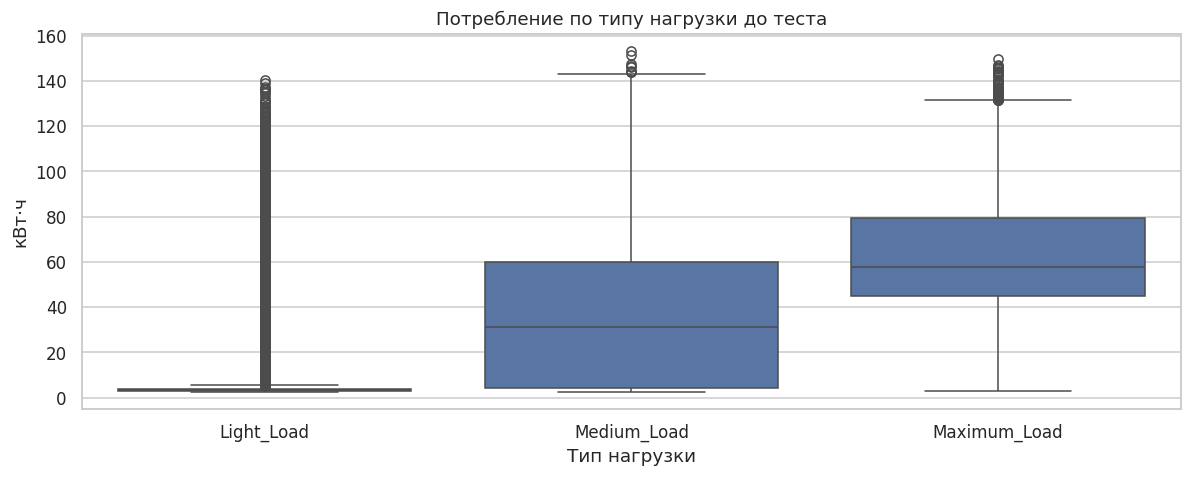

Вывод:  Группы различаются по среднему уровню потребления, но их диапазоны перекрываются. Название Maximum_Load не означает, что любое такое наблюдение выше любого Medium_Load. Для практического использования нужно подтвердить, что категория известна в момент выдачи прогноза.

In [83]:
load_order = ['Light_Load', 'Medium_Load', 'Maximum_Load']
display(eda.groupby('Load_Type')['Usage_kWh'].agg(['count', 'mean', 'median', 'max'])
        .reindex(load_order).round(2))
fig, ax = plt.subplots()
sns.boxplot(data=eda, x='Load_Type', y='Usage_kWh', order=load_order, ax=ax)
ax.set(title='Потребление по типу нагрузки до теста', xlabel='Тип нагрузки', ylabel='кВт·ч')
plt.tight_layout(); plt.show()
conclusion('Группы различаются по среднему уровню потребления, но их диапазоны '
           'перекрываются. Название Maximum_Load не означает, что любое такое '
           'наблюдение выше любого Medium_Load. Для практического использования '
           'нужно подтвердить, что категория известна в момент выдачи прогноза.')

### Шаг 12. Дни недели

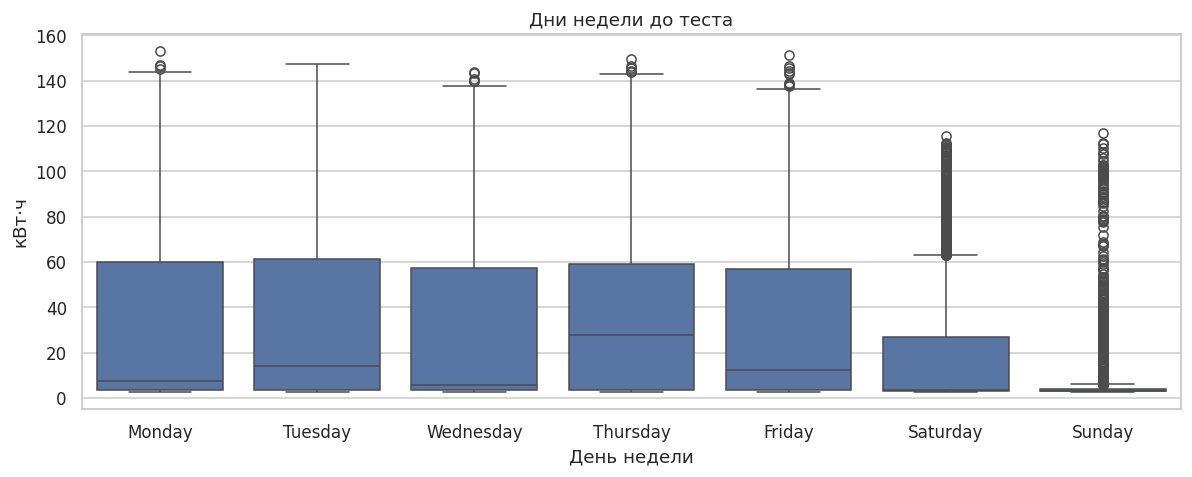

,"Среднее, кВт·ч"
WeekStatus,
Weekday,34.19
Weekend,11.88


Вывод:  В будни среднее равно 34.19 кВт·ч, в выходные - 11.88. Календарь помогает описать рабочий ритм. Проверяем, даёт ли отдельный признак выходного дополнительную пользу, когда день недели уже известен.

In [84]:
day_order = ['Monday', 'Tuesday', 'Wednesday', 'Thursday', 'Friday', 'Saturday', 'Sunday']
fig, ax = plt.subplots()
sns.boxplot(data=eda, x='Day_of_week', y='Usage_kWh', order=day_order, ax=ax)
ax.set(title='Дни недели до теста', xlabel='День недели', ylabel='кВт·ч')
plt.tight_layout(); plt.show()
week_means = eda.groupby('WeekStatus')['Usage_kWh'].mean()
display(week_means.round(2).rename('Среднее, кВт·ч').to_frame())
conclusion(f'В будни среднее равно {week_means["Weekday"]:.2f} кВт·ч, '
           f'в выходные - {week_means["Weekend"]:.2f}. '
           'Календарь помогает описать рабочий ритм. Проверяем, даёт ли отдельный '
           'признак выходного дополнительную пользу, когда день недели уже известен.')

## Этап 3. Подготовка признаков
### Шаг 13. Календарь прогнозируемого интервала

Календарь следующего интервала известен заранее. Поэтому в момент 23:45 используем
дату и день недели следующей полуночи. Час кодируется с учётом минут, чтобы не
считать 23:45 и 23:00 одинаковыми.

In [85]:
def build_features(frame):
    out = frame.copy()
    out['Forecast_Date'] = out['date'] + STEP
    forecast = out['Forecast_Date'].dt
    out['forecast_hour'] = forecast.hour
    out['forecast_minute'] = forecast.minute
    out['Forecast_Day_of_week'] = forecast.day_name().astype(str)
    time_of_day = forecast.hour + forecast.minute / 60
    out['hour_sin'] = np.sin(2 * np.pi * time_of_day / 24)
    out['hour_cos'] = np.cos(2 * np.pi * time_of_day / 24)
    out['is_weekend'] = forecast.dayofweek.ge(5).astype(int)
    usage = out['Usage_kWh']
    out['rolling_mean_1h'] = usage.rolling(4, min_periods=4).mean()
    out['rolling_std_1h'] = usage.rolling(4, min_periods=4).std()
    out['lag_1h'] = usage.shift(4)
    out['lag_24h'] = usage.shift(96)
    out['lag_1week'] = usage.shift(672)
    # Значения в то же время, что прогнозируесый интервал, вчера и неделю назад.
    out['same_time_yesterday'] = usage.shift(95)
    out['same_time_last_week'] = usage.shift(671)
    return out

prepared = build_features(df_raw)
display(prepared[['date', 'Forecast_Date', 'forecast_hour', 'forecast_minute',
                  'Forecast_Day_of_week', 'hour_sin', 'hour_cos']].head())
conclusion('Календарные признаки относятся к тому интервалу, который прогнозируем. '
           'Синус и косинус делают конец и начало суток соседними значениями. ')

,date,Forecast_Date,forecast_hour,forecast_minute,Forecast_Day_of_week,hour_sin,hour_cos
0,2018-01-01 00:00:00,2018-01-01 00:15:00,0,15,Monday,0.065403,0.997859
1,2018-01-01 00:15:00,2018-01-01 00:30:00,0,30,Monday,0.130526,0.991445
2,2018-01-01 00:30:00,2018-01-01 00:45:00,0,45,Monday,0.195090,0.980785
3,2018-01-01 00:45:00,2018-01-01 01:00:00,1,0,Monday,0.258819,0.965926
4,2018-01-01 01:00:00,2018-01-01 01:15:00,1,15,Monday,0.321439,0.946930


Вывод:  Календарные признаки относятся к тому интервалу, который прогнозируем. Синус и косинус делают конец и начало суток соседними значениями. 

### Шаг 14. Гипотезы о новых признаках

1. Циклическое время суток поможет модели учитывать смену суточных режимов.
2. Выходной отличается от буднего дня, но отдельный флаг может дублировать день недели.
3. Среднее и изменчивость последнего часа, а также часовые, суточные и недельные лаги
   могут улучшить прогноз по сравнению с одним текущим показанием.

Все оконные признаки используют только текущие и прошлые значения. Текущий интервал
включён в окно, потому что к моменту прогноза уже завершён.

In [86]:
base_features = ['Usage_kWh', 'forecast_hour', 'forecast_minute', 'Forecast_Day_of_week']
cycle_features = ['hour_sin', 'hour_cos']
weekend_features = ['is_weekend']
history_features = ['rolling_mean_1h', 'rolling_std_1h', 'lag_1h', 'lag_24h',
                    'lag_1week', 'same_time_yesterday', 'same_time_last_week']
features = base_features + cycle_features + weekend_features + history_features
numeric_features = [c for c in features if c != 'Forecast_Day_of_week']
categorical_features = ['Forecast_Day_of_week']
feature_notes = pd.DataFrame([
    ['Usage_kWh', 'Текущий завершённый интервал', 'В момент получения показания'],
    ['Календарь', 'Дата следующего интервала', 'Заранее'],
    ['rolling_*', 'Четыре завершённых интервала до текущего включительно', 'В момент прогноза'],
    ['lag_1h / lag_24h / lag_1week', 'Значения 4 / 96 / 672 шага назад от текущего', 'Из истории'],
    ['same_time_*', '95 / 671 шаг назад от текущего', 'Из истории'],
    ['CO₂, реактивные показатели, Load_Type', 'Текущие показатели в CSV', 'Не подтверждено источником'],
], columns=['Признак', 'Что означает', 'Когда доступен'])
display(feature_notes)
conclusion('Чтобы предсказать 12:15, сезонный baseline берёт вчерашние 12:15, '
           'а не 12:00. Поэтому он сдвинут на 95 строк от текущих 12:00. '
           'Недельный - на 671. Признаки lag_24h и lag_1week имеют иной смысл '
           'и сдвиги 96 и 672.')

,Признак,Что означает,Когда доступен
0,Usage_kWh,Текущий завершённый интервал,В момент получения показания
1,Календарь,Дата следующего интервала,Заранее
2,rolling_*,Четыре завершённых интервала до текущего включ...,В момент прогноза
3,lag_1h / lag_24h / lag_1week,Значения 4 / 96 / 672 шага назад от текущего,Из истории
4,same_time_*,95 / 671 шаг назад от текущего,Из истории
5,"CO₂, реактивные показатели, Load_Type",Текущие показатели в CSV,Не подтверждено источником


Вывод:  Чтобы предсказать 12:15, сезонный baseline берёт вчерашние 12:15, а не 12:00. Поэтому он сдвинут на 95 строк от текущих 12:00. Недельный - на 671. Признаки lag_24h и lag_1week имеют иной смысл и сдвиги 96 и 672.

### Шаг 15. Цель на один шаг вперёд

In [87]:
prepared['Target_Next_15min'] = df_raw['Usage_kWh'].shift(-1)
prepared['Target_Date'] = df_raw['date'].shift(-1)
model_df = prepared.dropna(subset=features + ['Target_Next_15min', 'Target_Date']).copy()
model_df = model_df.reset_index(drop=True)
assert model_df['Target_Date'].eq(model_df['Forecast_Date']).all()
assert model_df['Target_Date'].sub(model_df['date']).eq(STEP).all()
display(model_df[['date', 'Usage_kWh', 'lag_1h', 'same_time_yesterday',
                  'Target_Date', 'Target_Next_15min']].head())
conclusion(f'Подготовлено {len(model_df):,} объектов. Первые 672 строки нужны '
           'для накопления недельной истории, а последняя не имеет известного '
           'следующего значения. Их исключили по одинаковому правилу для всех '
           'моделей и baseline. Цель всегда относится ровно к следующему интервалу.')

,date,Usage_kWh,lag_1h,same_time_yesterday,Target_Date,Target_Next_15min
0,2018-01-08 00:00:00,4.68,3.64,3.13,2018-01-08 00:15:00,3.78
1,2018-01-08 00:15:00,3.78,3.24,3.49,2018-01-08 00:30:00,3.38
2,2018-01-08 00:30:00,3.38,3.64,3.64,2018-01-08 00:45:00,3.31
3,2018-01-08 00:45:00,3.31,3.42,3.20,2018-01-08 01:00:00,3.89
4,2018-01-08 01:00:00,3.89,4.68,3.56,2018-01-08 01:15:00,3.35


Вывод:  Подготовлено 34,367 объектов. Первые 672 строки нужны для накопления недельной истории, а последняя не имеет известного следующего значения. Их исключили по одинаковому правилу для всех моделей и baseline. Цель всегда относится ровно к следующему интервалу.

### Шаг 16. Предварительная проверка гипотез

,Корреляция с будущим Usage
rolling_mean_1h,0.842
same_time_last_week,0.668
lag_1h,0.640
lag_1week,0.637
same_time_yesterday,0.606
lag_24h,0.575
rolling_std_1h,0.544
is_weekend,-0.294
hour_sin,-0.313
hour_cos,-0.439


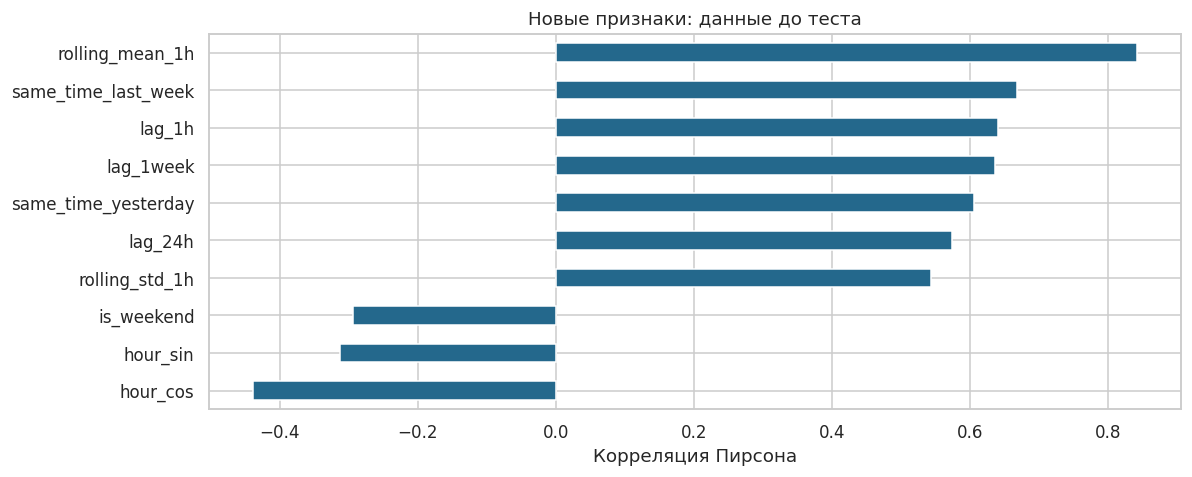

Вывод:  История содержит связь с будущим потреблением. Это основание проверить признаки, но не доказательство улучшения прогноза. Слабая отдельная корреляция синуса или косинуса не опровергает суточную цикличность. В шаге 27 сравним одинаковую модель с добавлением каждой группы и без неё.

In [88]:
eda_model = model_df.loc[model_df['Target_Date'] < TEST_START]
new_corr = eda_model[cycle_features + weekend_features + history_features +
                    ['Target_Next_15min']].corr()['Target_Next_15min'].drop('Target_Next_15min')
display(new_corr.sort_values(ascending=False).round(3).rename('Корреляция с будущим Usage').to_frame())
fig, ax = plt.subplots()
new_corr.sort_values().plot.barh(ax=ax, color='#24688c')
ax.set(xlabel='Корреляция Пирсона', title='Новые признаки: данные до теста')
plt.tight_layout(); plt.show()
conclusion('История содержит связь с будущим потреблением. Это основание '
           'проверить признаки, но не доказательство улучшения прогноза. '
           'Слабая отдельная корреляция синуса или косинуса не опровергает '
           'суточную цикличность. В шаге 27 сравним одинаковую модель '
           'с добавлением каждой группы и без неё.')

### Шаг 17. Итоговая проверка и стратегия предобработки

In [89]:
assert not model_df[features + ['Target_Next_15min']].isna().any().any()
assert np.isfinite(model_df[numeric_features + ['Target_Next_15min']].to_numpy()).all()
print('Число признаков:', len(features), '| Числовых:', len(numeric_features),
      '| Категориальных:', categorical_features)
display(pd.Series(features, name='Признаки основной модели').to_frame())
conclusion('После подготовки пропусков и бесконечностей нет. Значения '
           'потребления не обрезаем. Для sklearn используем One-Hot-кодирование '
           'категорий внутри пайплайна, CatBoost получает категории напрямую. '
           'Для обычной линейной регрессии отдельно проверим масштабирование.')

Число признаков: 14 | Числовых: 13 | Категориальных: ['Forecast_Day_of_week']


,Признаки основной модели
0,Usage_kWh
1,forecast_hour
2,forecast_minute
3,Forecast_Day_of_week
4,hour_sin
5,hour_cos
6,is_weekend
7,rolling_mean_1h
8,rolling_std_1h
9,lag_1h


Вывод:  После подготовки пропусков и бесконечностей нет. Значения потребления не обрезаем. Для sklearn используем One-Hot-кодирование категорий внутри пайплайна, CatBoost получает категории напрямую. Для обычной линейной регрессии отдельно проверим масштабирование.

## Этап 4. Валидация и защита от утечек
### Шаг 18. Три хронологических уровня

Сначала выделяем исторический тест с 20 октября 2018 года по моменту прогноза.
Более раннюю часть называем `train`. Внутри неё первые 75% используются для поиска
параметров с временной CV, последние 25% - отдельный период выбора победителя.

На каждой границе исключаем одну строку (`gap=1`): все обучающие целевые даты
должны быть строго раньше первого момента прогнозирования в следующем блоке.
При обучении уже после
получения текущего измерения `gap=0` не обязательно был бы утечкой, но здесь
одинаково используем более строгую схему.

In [90]:
train_df = model_df.loc[(model_df['date'] < TEST_START) &
                       (model_df['Target_Date'] < TEST_START)].copy().reset_index(drop=True)
test_df = model_df.loc[model_df['date'] >= TEST_START].copy().reset_index(drop=True)
cut = int(len(train_df) * 0.75)
select_start = train_df['date'].iloc[cut]
search_df = train_df.loc[train_df['Target_Date'] < select_start].copy().reset_index(drop=True)
select_df = train_df.loc[train_df['date'] >= select_start].copy().reset_index(drop=True)

X_search, y_search = search_df[features], search_df['Target_Next_15min']
X_select, y_select = select_df[features], select_df['Target_Next_15min']
X_train, y_train = train_df[features], train_df['Target_Next_15min']
X_test, y_test = test_df[features], test_df['Target_Next_15min']
split_table = pd.DataFrame([
    [name, len(part), part['date'].min(), part['date'].max(), part['Target_Date'].max()]
    for name, part in [('Поиск параметров', search_df), ('Выбор модели', select_df),
                       ('Весь train для финального обучения', train_df), ('Тест', test_df)]
], columns=['Период', 'Объектов', 'Первый прогноз', 'Последний прогноз', 'Последняя цель'])
display(split_table)
conclusion('Поиск параметров видит только раннюю историю. Победителя выбираем '
           'на следующем временном отрезке, который не участвовал в поиске. '
           'После фиксации решения модели обучатся заново на всём train. '
           'Тест до этого не используется для вычисления качества.')

,Период,Объектов,Первый прогноз,Последний прогноз,Последняя цель
0,Поиск параметров,20518,2018-01-08 00:00:00,2018-08-09 17:15:00,2018-08-09 17:30:00
1,Выбор модели,6840,2018-08-09 17:45:00,2018-10-19 23:30:00,2018-10-19 23:45:00
2,Весь train для финального обучения,27359,2018-01-08 00:00:00,2018-10-19 23:30:00,2018-10-19 23:45:00
3,Тест,7007,2018-10-20 00:00:00,2018-12-31 23:30:00,2018-12-31 23:45:00


Вывод:  Поиск параметров видит только раннюю историю. Победителя выбираем на следующем временном отрезке, который не участвовал в поиске. После фиксации решения модели обучатся заново на всём train. Тест до этого не используется для вычисления качества.

### Шаг 19. Метрики

MAE - основная: на сколько кВт·ч в среднем ошибается прогноз одного интервала.
RMSE: сильнее реагирует на большие ошибки. Это полезно при оценке риска промахов.
R²: сравнение суммы квадратов ошибок с прогнозом средним на оцениваемом периоде.


In [91]:
def evaluate(y_true, y_pred):
    y_true, y_pred = np.asarray(y_true), np.asarray(y_pred)
    assert y_true.shape == y_pred.shape and np.isfinite(y_pred).all()
    return {'MAE': mean_absolute_error(y_true, y_pred),
            'RMSE': np.sqrt(mean_squared_error(y_true, y_pred)),
            'R2': r2_score(y_true, y_pred)}

scoring = {'MAE': 'neg_mean_absolute_error', 'RMSE': 'neg_root_mean_squared_error', 'R2': 'r2'}
conclusion('Качество всех моделей будет измеряться на одних и тех же строках '
           'и в одинаковых единицах. Чем ниже MAE и RMSE, тем лучше. '
           'Для R² большее значение лучше, но одна эта метрика не описывает ошибки на пиках.')

Вывод:  Качество всех моделей будет измеряться на одних и тех же строках и в одинаковых единицах. Чем ниже MAE и RMSE, тем лучше. Для R² большее значение лучше, но одна эта метрика не описывает ошибки на пиках.

### Шаг 20. Временная кросс-валидация внутри периода поиска

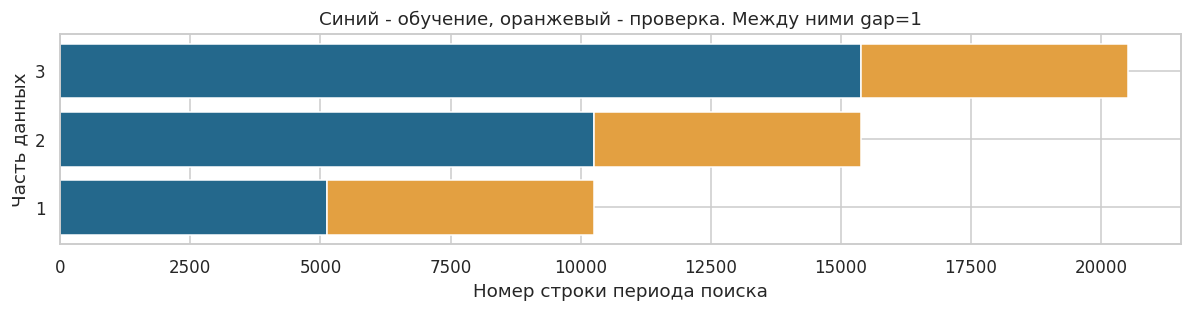

Вывод:  Каждая часть данных учится на прошлом и проверяется на более позднем отрезке. Периоды выбора модели и теста в эту CV не входят. Среднее и разброс по фолдам помогут сравнивать настройки, но не служат самостоятельным статистическим доказательством равенства моделей.

In [92]:
cv = TimeSeriesSplit(n_splits=N_SPLITS, gap=1)
cv_splits = list(cv.split(X_search))
fig, ax = plt.subplots(figsize=(11, 3))
for fold, (tr, va) in enumerate(cv_splits, 1):
    ax.barh(fold, len(tr), left=tr[0], color='#24688c')
    ax.barh(fold, len(va), left=va[0], color='#e3a041')
    assert search_df['Target_Date'].iloc[tr].max() < search_df['date'].iloc[va].min()
ax.set(yticks=range(1, N_SPLITS + 1), xlabel='Номер строки периода поиска',
       ylabel='Часть данных', title='Синий - обучение, оранжевый - проверка. Между ними gap=1')
plt.tight_layout(); plt.show()
conclusion('Каждая часть данных учится на прошлом и проверяется на более позднем отрезке. '
           'Периоды выбора модели и теста в эту CV не входят. Среднее и разброс '
           'по фолдам помогут сравнивать настройки, но не служат самостоятельным '
           'статистическим доказательством равенства моделей.')

### Шаг 21. Проверки отсутствия доступа к будущему

In [93]:
assert train_df['Target_Date'].max() < test_df['date'].min()
assert search_df['Target_Date'].max() < select_df['date'].min()
assert all('Target' not in c and 'Date' not in c for c in features)

check_at = 2000
changed_future = df_raw.copy()
changed_future.loc[check_at + 1:, 'Usage_kWh'] += 10000
features_original = build_features(df_raw)
features_changed = build_features(changed_future)
pd.testing.assert_frame_equal(features_original.loc[:check_at, features],
                              features_changed.loc[:check_at, features])
assert prepared['same_time_yesterday'].iloc[1000] == df_raw['Usage_kWh'].iloc[905]
assert prepared['same_time_last_week'].iloc[1000] == df_raw['Usage_kWh'].iloc[329]
print('Проверены границы целевых дат, шаг горизонта, выравнивание baseline и причинность признаков.')
conclusion('Будущие значения не влияют на признаки уже прошедших моментов. '
           'Предобработка будет обучаться внутри каждого пайплайна только на его train.')

Проверены границы целевых дат, шаг горизонта, выравнивание baseline и причинность признаков.


Вывод:  Будущие значения не влияют на признаки уже прошедших моментов. Предобработка будет обучаться внутри каждого пайплайна только на его train.

Сравнение способов масштабирования

Сравниваем без скейлера, StandardScaler и MinMaxScaler на одинаковых CV-фолдах.
В линейной модели исключаем `is_weekend`, потому что он точно выражается через
One-Hot дня недели. Одну категорию One-Hot удаляем, чтобы она не дублировала константу.

,Модель,MAE mean,MAE std,RMSE mean,R2 mean,R2 std
0,Без масштабирования,6.71918,0.48139,11.76979,0.8641,0.00792
1,StandardScaler,6.71918,0.48139,11.76979,0.8641,0.00792
2,MinMaxScaler,6.71918,0.48139,11.76979,0.8641,0.00792


,Способ,Число коэффициентов,Максимальный модуль,Средний модуль
0,Без масштабирования,18,2.4754,0.5083
1,StandardScaler,18,26.7795,3.7479
2,MinMaxScaler,18,116.9883,15.2798


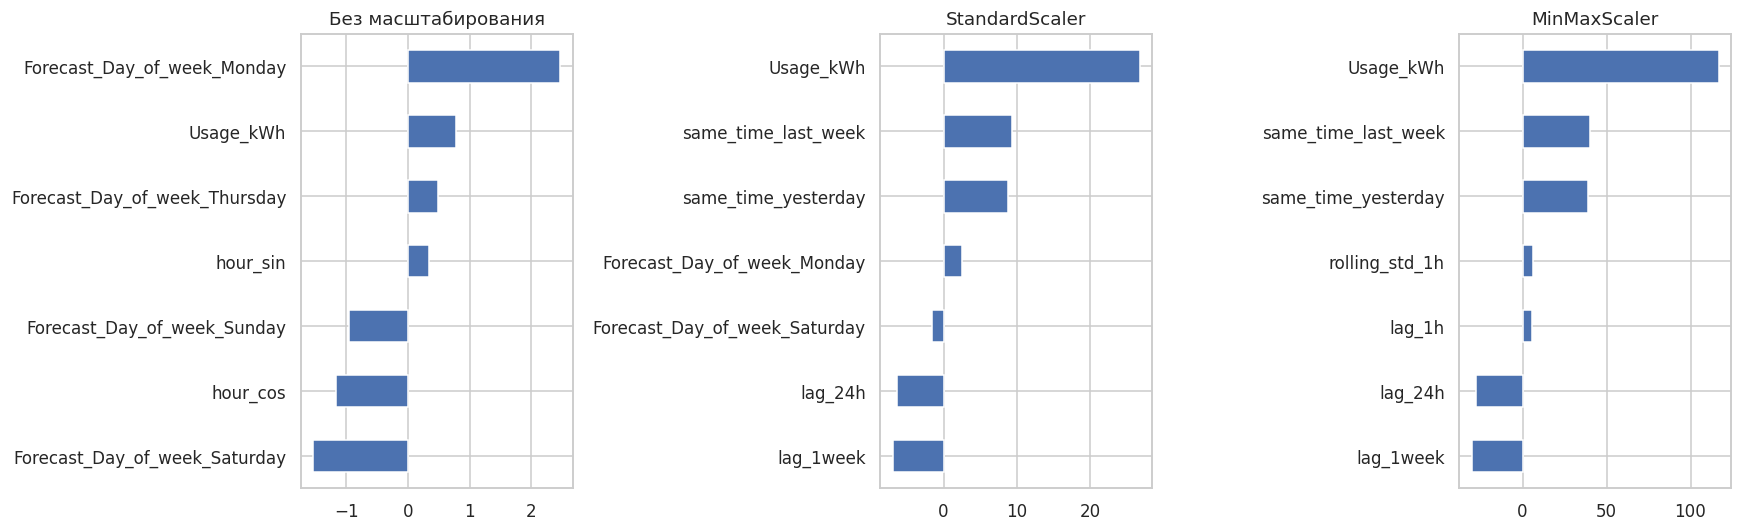

Вывод:  Разница между наибольшим и наименьшим CV MAE скейлеров равна 0.000000 кВт·ч. Для обычной OLS-регрессии изменение единиц признаков теоретически не меняет прогноз при эквивалентной параметризации. Оставляем StandardScaler. Масштабы коэффициентов меняются, их число - нет. Числовые коэффициенты после стандартизации относятся к изменению на одно стандартное отклонение, а категории остаются индикаторами, все коэффициенты не становятся автоматически причинными или полностью сопоставимыми.

In [94]:
linear_numeric = [c for c in numeric_features if c != 'is_weekend']

def make_preprocessor(scaler='passthrough', linear=False):
    return ColumnTransformer([
        ('num', scaler, linear_numeric if linear else numeric_features),
        ('cat', OneHotEncoder(drop='first', handle_unknown='ignore', sparse_output=False),
         categorical_features)
    ], remainder='drop')

def make_lr(scaler):
    return Pipeline([('preprocessor', make_preprocessor(scaler, linear=True)),
                     ('model', LinearRegression())])

def cv_table_row(name, scores):
    return {'Модель': name, 'MAE mean': -scores['test_MAE'].mean(),
            'MAE std': scores['test_MAE'].std(ddof=0),
            'RMSE mean': -scores['test_RMSE'].mean(),
            'R2 mean': scores['test_R2'].mean(),
            'R2 std': scores['test_R2'].std(ddof=0)}

scalers = {'Без масштабирования': 'passthrough',
           'StandardScaler': StandardScaler(), 'MinMaxScaler': MinMaxScaler()}
scaling_rows, coefficient_rows, coefficient_series, scaling_scores = [], [], {}, {}
for name, scaler in scalers.items():
    pipe = make_lr(scaler)
    scores = cross_validate(pipe, X_search, y_search, cv=cv_splits, scoring=scoring, n_jobs=1)
    scaling_scores[name] = scores
    scaling_rows.append(cv_table_row(name, scores))
    pipe.fit(X_search, y_search)
    coefs = pipe.named_steps['model'].coef_
    coefficient_rows.append({'Способ': name, 'Число коэффициентов': len(coefs),
                             'Максимальный модуль': np.abs(coefs).max(),
                             'Средний модуль': np.abs(coefs).mean()})
    coefficient_series[name] = pd.Series(coefs, index=pipe.named_steps['preprocessor'].get_feature_names_out())
scaling_results = pd.DataFrame(scaling_rows)
display(scaling_results.round(5))
display(pd.DataFrame(coefficient_rows).round(4))
fig, axes = plt.subplots(1, 3, figsize=(16, 5))
for ax, (name, series) in zip(axes, coefficient_series.items()):
    top = series.loc[series.abs().nlargest(7).index].sort_values()
    top.index = top.index.str.replace('num__', '', regex=False).str.replace('cat__', '', regex=False)
    top.plot.barh(ax=ax)
    ax.set_title(name)
plt.tight_layout(); plt.show()
scale_spread = scaling_results['MAE mean'].max() - scaling_results['MAE mean'].min()
conclusion(f'Разница между наибольшим и наименьшим CV MAE скейлеров равна '
           f'{scale_spread:.6f} кВт·ч. Для обычной OLS-регрессии изменение '
           'единиц признаков теоретически не меняет прогноз при эквивалентной '
           'параметризации. Оставляем StandardScaler. Масштабы коэффициентов '
           'меняются, их число - нет. Числовые коэффициенты после стандартизации '
           'относятся к изменению на одно стандартное отклонение, а категории '
           'остаются индикаторами, все коэффициенты не становятся автоматически '
           'причинными или полностью сопоставимыми.')

## Этап 5. Моделирование и оптимизация
### Шаг 22. Три baseline и линейная регрессия

Первые оценки здесь и далее получены на периоде выбора модели, не на тесте.
Inertia прогнозирует следующие 15 минут как текущие, Day - то же время вчера,
Week - то же время неделю назад. Ни один baseline не обучается на будущих целях.

In [95]:
baseline_columns = {'Инерция': 'Usage_kWh', 'Вчера в то же время': 'same_time_yesterday',
                    'Неделю назад': 'same_time_last_week'}
selection_predictions = {name: X_select[col].to_numpy() for name, col in baseline_columns.items()}
lr_pipe = make_lr(StandardScaler())
lr_pipe.fit(X_search, y_search)
selection_predictions['Линейная регрессия'] = lr_pipe.predict(X_select)
candidate_models = {'Линейная регрессия': lr_pipe}

def selection_table():
    return pd.DataFrame([{'Модель': name, **evaluate(y_select, pred)}
                         for name, pred in selection_predictions.items()]).sort_values('MAE')

display(selection_table().round(4))
naive_mae = evaluate(y_select, selection_predictions['Инерция'])['MAE']
linear_mae = evaluate(y_select, selection_predictions['Линейная регрессия'])['MAE']
comparison = 'лучше' if linear_mae < naive_mae else 'хуже или на уровне'
conclusion(f'На периоде выбора MAE инерции = {naive_mae:.3f}, линейной регрессии = '
           f'{linear_mae:.3f} кВт·ч. Линейная модель {comparison} инерционного '
           'прогноза. Причину различия нельзя установить по одной метрике: '
           'возможны нелинейные режимы, шум и изменение условий во времени.')

,Модель,MAE,RMSE,R2
0,Инерция,5.6698,12.7660,0.8308
3,Линейная регрессия,6.1441,11.2064,0.8696
2,Неделю назад,12.5938,24.5867,0.3725
1,Вчера в то же время,15.0048,28.7109,0.1443


Вывод:  На периоде выбора MAE инерции = 5.670, линейной регрессии = 6.144 кВт·ч. Линейная модель хуже или на уровне инерционного прогноза. Причину различия нельзя установить по одной метрике: возможны нелинейные режимы, шум и изменение условий во времени.

### Шаг 23. Random Forest: базовая конфигурация и случайный поиск



In [96]:
rf_base = Pipeline([('preprocessor', make_preprocessor()),
                    ('model', RandomForestRegressor(n_estimators=120,
                     min_samples_leaf=2, random_state=SEED, n_jobs=THREADS))])
rf_base.fit(X_search, y_search)
selection_predictions['Random Forest: базовый'] = rf_base.predict(X_select)
candidate_models['Random Forest: базовый'] = rf_base
param_distributions = {'model__n_estimators': [100, 160],
                       'model__max_depth': [12, 20, None],
                       'model__min_samples_leaf': [1, 3, 6],
                       'model__max_features': [0.6, 1.0]}
rf_search = RandomizedSearchCV(rf_base, param_distributions=param_distributions,
                             n_iter=RF_SEARCH_ITER, scoring='neg_mean_absolute_error',
                             cv=cv_splits, random_state=SEED, n_jobs=1, refit=True, verbose=0)
rf_search.fit(X_search, y_search)
rf_best = rf_search.best_estimator_
candidate_models['Random Forest: поиск'] = rf_best
selection_predictions['Random Forest: поиск'] = rf_best.predict(X_select)
print('Лучшие параметры поиска:', rf_search.best_params_)
print('CV MAE лучшего кандидата:', round(-rf_search.best_score_, 4))
display(selection_table().loc[lambda x: x['Модель'].str.startswith('Random Forest')].round(4))
rf_before = evaluate(y_select, selection_predictions['Random Forest: базовый'])
rf_after = evaluate(y_select, selection_predictions['Random Forest: поиск'])
rf_gain = (rf_before['MAE'] - rf_after['MAE']) / rf_before['MAE'] * 100
conclusion(f'На отдельном периоде выбора MAE изменился с {rf_before["MAE"]:.3f} '
           f'до {rf_after["MAE"]:.3f}; относительное улучшение = {rf_gain:+.2f}%. '
           f'RMSE: {rf_before["RMSE"]:.3f} → {rf_after["RMSE"]:.3f}. '
           'Положительный процент означает улучшение, отрицательный - ухудшение.')

Лучшие параметры поиска: {'model__n_estimators': 100, 'model__min_samples_leaf': 3, 'model__max_features': 0.6, 'model__max_depth': None}
CV MAE лучшего кандидата: 5.0898


,Модель,MAE,RMSE,R2
5,Random Forest: поиск,4.3027,9.1425,0.9132
4,Random Forest: базовый,4.3041,9.2781,0.9106


Вывод:  На отдельном периоде выбора MAE изменился с 4.304 до 4.303; относительное улучшение = +0.03%. RMSE: 9.278 → 9.142. Положительный процент означает улучшение, отрицательный - ухудшение.

### Шаг 24. CatBoost: ранняя остановка и корректное переобучение

Для базовой конфигурации выделяем хвост периода поиска, который не пересекается
с периодом выбора модели. Ранняя остановка использует MAE. После выбора числа
итераций обучаем CatBoost заново на всём периоде поиска с фиксированным числом деревьев.


In [97]:
def make_cb(**params):
    defaults = dict(iterations=400, depth=6, learning_rate=0.05,
                    loss_function='RMSE', eval_metric='MAE', random_seed=SEED,
                    cat_features=categorical_features, thread_count=THREADS,
                    allow_writing_files=False, verbose=False)
    defaults.update(params)
    return CatBoostRegressor(**defaults)

inner_cut = int(len(X_search) * 0.85)
inner_train = np.arange(inner_cut - 1)
inner_stop = np.arange(inner_cut, len(X_search))
assert search_df['Target_Date'].iloc[inner_train].max() < search_df['date'].iloc[inner_stop].min()
cb_stop = make_cb(iterations=700, early_stopping_rounds=60)
cb_stop.fit(X_search.iloc[inner_train], y_search.iloc[inner_train],
            eval_set=(X_search.iloc[inner_stop], y_search.iloc[inner_stop]))
base_iterations = cb_stop.get_best_iteration() + 1
assert base_iterations > 0
cb_base = make_cb(iterations=base_iterations)
cb_base.fit(X_search, y_search)
candidate_models['CatBoost: базовый'] = cb_base
selection_predictions['CatBoost: базовый'] = cb_base.predict(X_select)
print('Число итераций по внутренней ранней остановке:', base_iterations)
display(selection_table().loc[lambda x: x['Модель'].str.startswith('CatBoost')].round(4))
conclusion('Число деревьев выбрано на внутреннем хвосте, после чего базовый '
           'CatBoost обучен на всём периоде поиска. Ни отдельный период выбора '
           'модели, ни тест не использовались для ранней остановки.')

Число итераций по внутренней ранней остановке: 700


,Модель,MAE,RMSE,R2
6,CatBoost: базовый,4.4812,9.1507,0.9131


Вывод:  Число деревьев выбрано на внутреннем хвосте, после чего базовый CatBoost обучен на всём периоде поиска. Ни отдельный период выбора модели, ни тест не использовались для ранней остановки.


### Шаг 25. Optuna для CatBoost

Оптимизируем средний MAE на тех же трёх CV-фолдах. Каждая конфигурация оценивается
с фиксированным числом деревьев, без ранней остановки на оцениваемом фолде.
Лучшее число итераций выбирается по CV вместе с остальными параметрами;
отдельный период выбора модели в этом поиске не участвует.


Лучшие параметры: {'iterations': 600, 'depth': 7, 'learning_rate': 0.044753162755625034, 'l2_leaf_reg': 1.8933568262114306}
Лучший CV MAE: 5.154


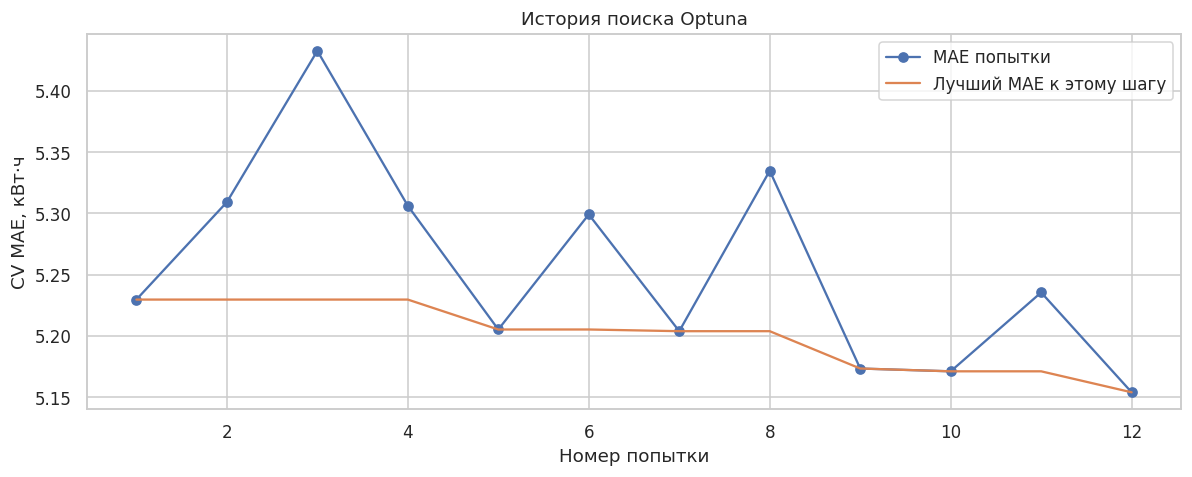

,Модель,MAE,RMSE,R2
7,CatBoost: Optuna,4.4328,9.1213,0.9136
6,CatBoost: базовый,4.4812,9.1507,0.9131


Вывод:  На отдельном периоде выбора MAE изменился с 4.481 до 4.433 кВт·ч; улучшение = +1.08%. Проверено 12 настроек.

In [98]:
def objective(trial):
    params = {'iterations': trial.suggest_categorical('iterations', [250, 400, 600]),
              'depth': trial.suggest_int('depth', 4, 7),
              'learning_rate': trial.suggest_float('learning_rate', 0.025, 0.15, log=True),
              'l2_leaf_reg': trial.suggest_float('l2_leaf_reg', 1.0, 12.0, log=True)}
    scores = []
    for tr, va in cv_splits:
        model = make_cb(**params)
        model.fit(X_search.iloc[tr], y_search.iloc[tr])
        scores.append(mean_absolute_error(y_search.iloc[va], model.predict(X_search.iloc[va])))
    trial.set_user_attr('mae_folds', scores)
    return float(np.mean(scores))

study = optuna.create_study(direction='minimize',
                           sampler=optuna.samplers.TPESampler(seed=SEED, n_startup_trials=4))
study.optimize(objective, n_trials=OPTUNA_TRIALS, n_jobs=1, show_progress_bar=False)
cb_tuned = make_cb(**study.best_params)
cb_tuned.fit(X_search, y_search)
candidate_models['CatBoost: Optuna'] = cb_tuned
selection_predictions['CatBoost: Optuna'] = cb_tuned.predict(X_select)
print('Лучшие параметры:', study.best_params)
print('Лучший CV MAE:', round(study.best_value, 4))
trial_values = np.array([t.value for t in study.trials])
fig, ax = plt.subplots()
ax.plot(np.arange(1, len(trial_values)+1), trial_values, 'o-', label='MAE попытки')
ax.plot(np.arange(1, len(trial_values)+1), np.minimum.accumulate(trial_values), label='Лучший MAE к этому шагу')
ax.set(xlabel='Номер попытки', ylabel='CV MAE, кВт·ч', title='История поиска Optuna')
ax.legend(); plt.tight_layout(); plt.show()
cb_before = evaluate(y_select, selection_predictions['CatBoost: базовый'])
cb_after = evaluate(y_select, selection_predictions['CatBoost: Optuna'])
cb_gain = (cb_before['MAE'] - cb_after['MAE']) / cb_before['MAE'] * 100
display(selection_table().loc[lambda x: x['Модель'].str.startswith('CatBoost')].round(4))
conclusion(f'На отдельном периоде выбора MAE изменился с {cb_before["MAE"]:.3f} '
           f'до {cb_after["MAE"]:.3f} кВт·ч; улучшение = {cb_gain:+.2f}%. '
           f'Проверено {OPTUNA_TRIALS} настроек.')

### Шаг 26. Сравнение кандидатов на периоде выбора

Все модели здесь обучены на одинаковом периоде поиска. Победитель определяется
по наименьшему MAE. Тест не используется для этого решения. Сначала завершим
диагностику признаков и CV в шаге 27, затем зафиксируем выбор и выполним итоговую оценку.

,Модель,MAE,RMSE,R2
0,Random Forest: поиск,4.3027,9.1425,0.9132
1,Random Forest: базовый,4.3041,9.2781,0.9106
2,CatBoost: Optuna,4.4328,9.1213,0.9136
3,CatBoost: базовый,4.4812,9.1507,0.9131
4,Инерция,5.6698,12.7660,0.8308
5,Линейная регрессия,6.1441,11.2064,0.8696
6,Неделю назад,12.5938,24.5867,0.3725
7,Вчера в то же время,15.0048,28.7109,0.1443


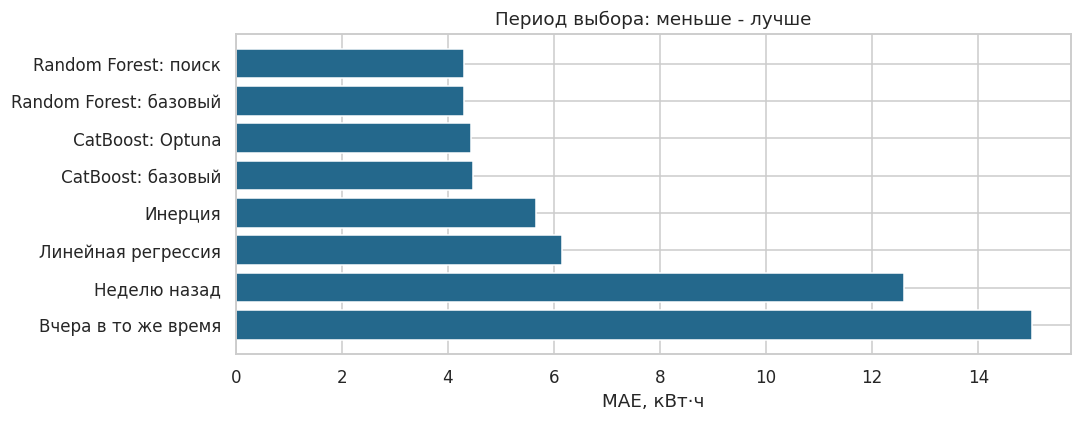

Вывод:  По заранее заданному правилу выбираем «Random Forest: поиск». Это решение основано на будущем относительно периода поиска отрезке, но всё ещё внутри train. Победитель тестовой таблицы впоследствии может оказаться другим; это не повод менять выбор задним числом.

In [99]:
selection_results = selection_table().reset_index(drop=True)
display(selection_results.round(4))
winner_name = selection_results.iloc[0]['Модель']
fig, ax = plt.subplots(figsize=(10, 4))
ax.barh(selection_results['Модель'], selection_results['MAE'], color='#24688c')
ax.invert_yaxis(); ax.set(xlabel='MAE, кВт·ч', title='Период выбора: меньше - лучше')
plt.tight_layout(); plt.show()
conclusion(f'По заранее заданному правилу выбираем «{winner_name}». '
           'Это решение основано на будущем относительно периода поиска отрезке, '
           'но всё ещё внутри train. Победитель тестовой таблицы впоследствии '
           'может оказаться другим; это не повод менять выбор задним числом.')

### Шаг 27. Стабильность, проверка новых признаков и границы интерпретации

CV-результаты ниже относятся только к периоду поиска. Настройки уже выбирались
на этих фолдах, поэтому эти числа не являются независимой оценкой настроенных
моделей. Отдельный период выбора и последующий тест дают дополнительные проверки.
Разница средних меньше разброса не доказывает статистическую эквивалентность.

In [100]:
cv_rows = [cv_table_row('Линейная регрессия', scaling_scores['StandardScaler'])]
rf_scores = cross_validate(rf_best, X_search, y_search, cv=cv_splits, scoring=scoring, n_jobs=1)
cv_rows.append(cv_table_row('Random Forest: поиск', rf_scores))
cb_scores = {'test_MAE': [], 'test_RMSE': [], 'test_R2': []}
for tr, va in cv_splits:
    model = make_cb(**study.best_params)
    model.fit(X_search.iloc[tr], y_search.iloc[tr])
    met = evaluate(y_search.iloc[va], model.predict(X_search.iloc[va]))
    cb_scores['test_MAE'].append(-met['MAE'])
    cb_scores['test_RMSE'].append(-met['RMSE'])
    cb_scores['test_R2'].append(met['R2'])
cb_scores = {k: np.asarray(v) for k, v in cb_scores.items()}
cv_rows.append(cv_table_row('CatBoost: Optuna', cb_scores))
for name, col in baseline_columns.items():
    fold_metrics = [evaluate(y_search.iloc[va], X_search.iloc[va][col]) for _, va in cv_splits]
    scores = {'test_MAE': -np.array([m['MAE'] for m in fold_metrics]),
              'test_RMSE': -np.array([m['RMSE'] for m in fold_metrics]),
              'test_R2': np.array([m['R2'] for m in fold_metrics])}
    cv_rows.append(cv_table_row(name, scores))
cv_summary = pd.DataFrame(cv_rows).sort_values('MAE mean')
display(cv_summary.round(4))
conclusion('Таблица показывает среднюю ошибку и её изменение между временными '
           'отрезками. Это полезно для диагностики, но трёх фолдов недостаточно, '
           'чтобы объявлять модели статистически одинаковыми или устойчивыми '
           'при любых будущих изменениях производства.')

,Модель,MAE mean,MAE std,RMSE mean,R2 mean,R2 std
1,Random Forest: поиск,5.0898,0.6219,10.2090,0.8976,0.0131
2,CatBoost: Optuna,5.1540,0.5365,10.0005,0.9018,0.0097
3,Инерция,6.1485,0.3488,13.6660,0.8167,0.0074
0,Линейная регрессия,6.7192,0.4814,11.7698,0.8641,0.0079
5,Неделю назад,13.0068,0.6643,24.4877,0.4062,0.0677
4,Вчера в то же время,14.9852,1.6947,27.3360,0.2668,0.0847


Вывод:  Таблица показывает среднюю ошибку и её изменение между временными отрезками. Это полезно для диагностики, но трёх фолдов недостаточно, чтобы объявлять модели статистически одинаковыми или устойчивыми при любых будущих изменениях производства.

#### Проверка пользы групп признаков

Используем одну заранее фиксированную конфигурацию CatBoost, одинаковые фолды и
одинаковые строки. При каждой проверке меняется только набор признаков. Сначала
добавляем группы к базовому набору; затем удаляем по одной из полного набора.
Это проверка конкретных гипотез, а не доказательство причинного влияния.

In [ ]:
feature_sets = {
    'Базовые': base_features,
    'Базовые + циклическое время': base_features + cycle_features,
    'Базовые + выходной': base_features + weekend_features,
    'Базовые + история': base_features + history_features,
    'Полный набор': features,
    'Полный без циклического времени': [c for c in features if c not in cycle_features],
    'Полный без выходного': [c for c in features if c not in weekend_features],
    'Полный без истории': [c for c in features if c not in history_features],
}
ablation_rows = []
for label, cols in feature_sets.items():
    scores = []
    for tr, va in cv_splits:
        model = make_cb(iterations=250, depth=6, learning_rate=0.05)
        model.fit(X_search.iloc[tr][cols], y_search.iloc[tr])
        scores.append(mean_absolute_error(y_search.iloc[va], model.predict(X_search.iloc[va][cols])))
    ablation_rows.append({'Набор': label, 'Признаков': len(cols),
                          'CV MAE': np.mean(scores), 'CV std': np.std(scores)})
ablation = pd.DataFrame(ablation_rows)
base_ablation_mae = ablation.loc[ablation['Набор'].eq('Базовые'), 'CV MAE'].iloc[0]
ablation['Изменение MAE против базовых'] = ablation['CV MAE'] - base_ablation_mae
display(ablation.round(4))
parts = []
for label in ['Базовые + циклическое время', 'Базовые + выходной', 'Базовые + история']:
    value = ablation.loc[ablation['Набор'].eq(label), 'Изменение MAE против базовых'].iloc[0]
    parts.append(f'«{label}»: изменение MAE {value:+.3f} кВт·ч')
conclusion('; '.join(parts) + '. Отрицательное изменение означает улучшение. '
           'Полезность зависит от уже имеющихся признаков: выходной может дублировать '
           'день недели, а лаги - друг друга. Полный набор задан заранее для основного '
           'сравнения, эта диагностическая таблица не используется для новой настройки '
           'на периоде выбора или тесте.')

#### Дополнительный эксперимент: электрические измерения и тип нагрузки

Добавляем исходные показатели к основным признакам. Для обеих версий берём одну
и ту же фиксированную конфигурацию. Результат показывает возможную дополнительную
пользу, но применим только при подтверждении доступности показателей в момент прогноза.
Эксперимент не участвует в выборе основной модели.

In [ ]:
extra_features = ['Lagging_Current_Reactive.Power_kVarh',
                  'Leading_Current_Reactive_Power_kVarh', 'CO2(tCO2)',
                  'Lagging_Current_Power_Factor', 'Leading_Current_Power_Factor', 'Load_Type']
extended_rows = []
for label, cols, cats in [('История и календарь', features, categorical_features),
                          ('С дополнительными измерениями', features + extra_features,
                           categorical_features + ['Load_Type'])]:
    model = make_cb(iterations=250, depth=6, learning_rate=0.05, cat_features=cats)
    model.fit(search_df[cols], y_search)
    pred = model.predict(select_df[cols])
    extended_rows.append({'Набор': label, **evaluate(y_select, pred)})
extended_results = pd.DataFrame(extended_rows)
display(extended_results.round(4))
extra_delta = extended_results['MAE'].iloc[1] - extended_results['MAE'].iloc[0]
conclusion(f'На периоде выбора добавление измерений изменило MAE на '
           f'{extra_delta:+.3f} кВт·ч при одинаковой модели. Отрицательное значение '
           'означает улучшение. Даже если оно есть, без сведений о задержках данных '
           'нельзя обещать такой результат в работе предприятия. Основная модель '
           'остаётся основанной на истории потребления и календаре.')

#### Фиксация выбора, обучение на всём train и итоговый тест

Выбор модели и параметры зафиксированы. Для прозрачности оцениваем все заранее
заданные кандидаты за один итоговый этап, но не переопределяем победителя по тесту.
CatBoost обучается с фиксированными итерациями на всём train, ранняя остановка на
тесте или его части не выполняется. Базовые и настроенные модели видят одинаковый train.

,Модель,MAE,RMSE,R2,Выбрана до теста
0,Random Forest: поиск,4.0592,8.5124,0.9264,True
1,Random Forest: базовый,4.0766,8.6343,0.9243,False
2,CatBoost: Optuna,4.2187,8.5033,0.9265,False
3,CatBoost: базовый,4.2528,8.5366,0.9260,False
4,Инерция,5.4856,12.3698,0.8445,False
5,Линейная регрессия,5.9665,10.6639,0.8845,False
6,Неделю назад,12.5474,24.1242,0.4087,False
7,Вчера в то же время,15.0518,27.6198,0.2250,False


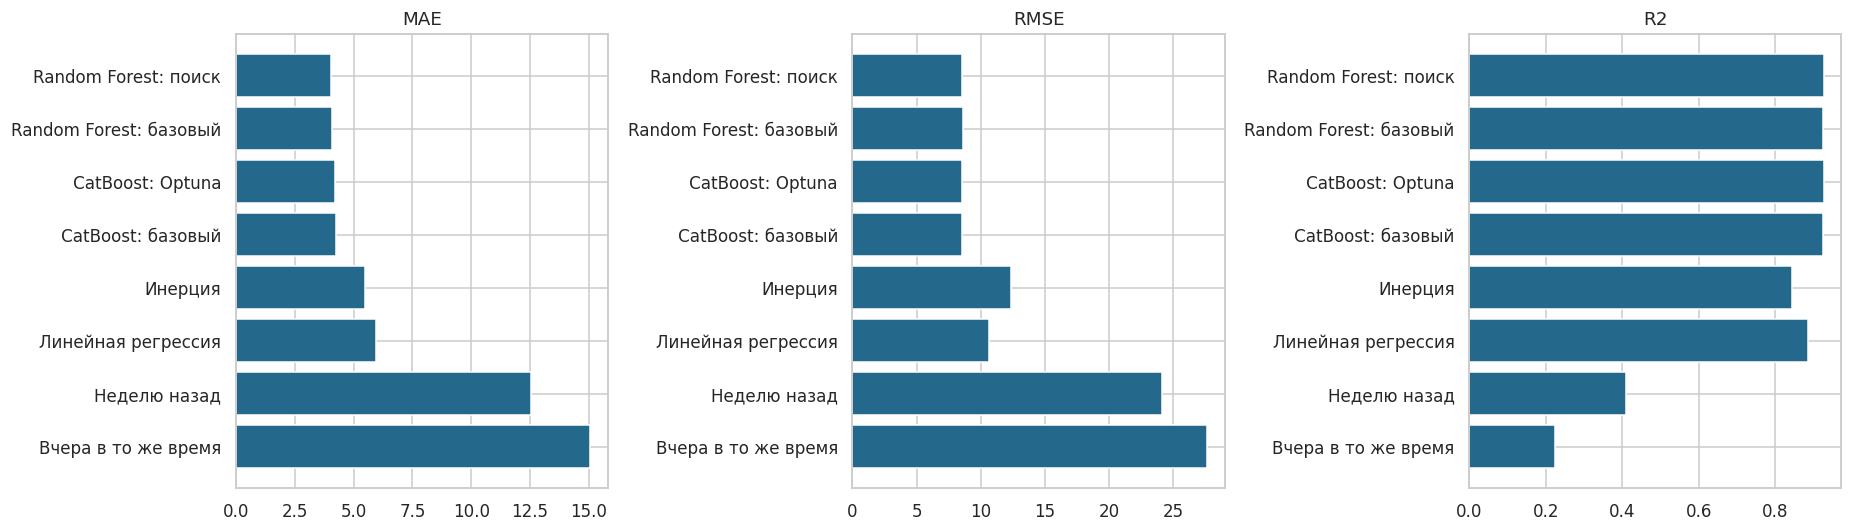

Вывод:  Заранее выбранная модель — «Random Forest: поиск». На тесте: MAE 4.059 кВт·ч, RMSE 8.512, R² 0.9264. Выигрыш по MAE против инерции: +26.00%. Минимальный тестовый MAE в сравнительной таблице у «Random Forest: поиск», но выбор не меняем задним числом. Новый период нужен для независимого подтверждения.

In [103]:
locked_winner_name = str(winner_name)
final_models, test_predictions = {}, {}
for name, col in baseline_columns.items():
    test_predictions[name] = X_test[col].to_numpy()
for name, fitted_candidate in candidate_models.items():
    final_model = (CatBoostRegressor(**fitted_candidate.get_params())
                   if isinstance(fitted_candidate, CatBoostRegressor)
                   else clone(fitted_candidate))
    final_model.fit(X_train, y_train)
    final_models[name] = final_model
    test_predictions[name] = final_model.predict(X_test)
test_results = pd.DataFrame([{'Модель': name, **evaluate(y_test, pred)}
                             for name, pred in test_predictions.items()])
test_results['Выбрана до теста'] = test_results['Модель'].eq(locked_winner_name)
test_results = test_results.sort_values('MAE').reset_index(drop=True)
display(test_results.round(4))
winner_pred = test_predictions[locked_winner_name]
winner_metrics = evaluate(y_test, winner_pred)
naive_test_metrics = evaluate(y_test, test_predictions['Инерция'])
winner_gain = 100 * (naive_test_metrics['MAE'] - winner_metrics['MAE']) / naive_test_metrics['MAE']
test_best_name = str(test_results.iloc[0]['Модель'])
fig, axes = plt.subplots(1, 3, figsize=(17, 5))
for ax, metric in zip(axes, ['MAE', 'RMSE', 'R2']):
    ax.barh(test_results['Модель'], test_results[metric], color='#24688c')
    ax.invert_yaxis(); ax.set_title(metric)
plt.tight_layout(); plt.show()
conclusion(f'Заранее выбранная модель — «{locked_winner_name}». На тесте: '
           f'MAE {winner_metrics["MAE"]:.3f} кВт·ч, RMSE {winner_metrics["RMSE"]:.3f}, '
           f'R² {winner_metrics["R2"]:.4f}. Выигрыш по MAE против инерции: '
           f'{winner_gain:+.2f}%. Минимальный тестовый MAE в сравнительной таблице '
           f'у «{test_best_name}», но выбор не меняем задним числом. '
           'Новый период нужен для независимого подтверждения.')

### Шаг 28. Факт и прогноз на разных участках теста

In [ ]:
target_dates = pd.DatetimeIndex(test_df['Target_Date'])
first_weekday = target_dates[target_dates.dayofweek < 5][0].normalize()
first_weekend = target_dates[target_dates.dayofweek >= 5][0].normalize()
peak_day = target_dates[int(np.argmax(y_test.to_numpy()))].normalize()
windows = [('Первый будний день', first_weekday), ('Первый выходной', first_weekend),
           ('День максимального потребления теста', peak_day)]
fig, axes = plt.subplots(3, 1, figsize=(13, 9))
for ax, (label, day) in zip(axes, windows):
    mask = (target_dates >= day) & (target_dates < day + pd.Timedelta(days=1))
    ax.plot(target_dates[mask], y_test.to_numpy()[mask], label='Факт', lw=1.5)
    ax.plot(target_dates[mask], winner_pred[mask], label='Прогноз', lw=1.2)
    ax.set(title=f'{label}: {day.date()}', ylabel='кВт·ч')
    ax.legend(loc='upper right')
plt.tight_layout(); plt.show()
conclusion('Показаны разные режимы работы, а не только первые несколько сотен '
           'точек. День максимальной нагрузки выбран специально для диагностики ')

### Шаг 29. Анализ ошибок, высоких нагрузок и изменений во времени

In [ ]:
errors = y_test.to_numpy() - winner_pred
abs_errors = np.abs(errors)
error_summary = pd.Series({'Средняя ошибка (факт - прогноз)': errors.mean(),
                           'Медиана ошибки': np.median(errors),
                           'Стандартное отклонение': errors.std(),
                           '90-й процентиль абсолютной ошибки': np.quantile(abs_errors, 0.90),
                           '95-й процентиль абсолютной ошибки': np.quantile(abs_errors, 0.95),
                           'Максимальная абсолютная ошибка': abs_errors.max(),
                           'Доля отрицательных прогнозов': (winner_pred < 0).mean()})
display(error_summary.round(4).rename('Значение').to_frame())
peak_threshold = float(y_train.quantile(0.9))
peak_mask = y_test.to_numpy() >= peak_threshold
segment_rows = []
for segment, mask in [('Обычная нагрузка', ~peak_mask), ('Высокая нагрузка', peak_mask)]:
    for label, pred in [('Выбранная модель', winner_pred), ('Инерция', test_predictions['Инерция'])]:
        segment_rows.append({'Участок': segment, 'Модель': label, 'Интервалов': int(mask.sum()),
                             **evaluate(y_test.to_numpy()[mask], pred[mask])})
print('Порог высокой нагрузки - 90-й процентиль train:', round(peak_threshold, 2), 'кВт·ч')
display(pd.DataFrame(segment_rows).round(4))
monthly_rows = []
for month in sorted(test_df['Target_Date'].dt.to_period('M').unique()):
    mask = test_df['Target_Date'].dt.to_period('M').eq(month).to_numpy()
    monthly_rows.append({'Месяц': str(month), 'Интервалов': int(mask.sum()),
                         **evaluate(y_test.to_numpy()[mask], winner_pred[mask])})
monthly_results = pd.DataFrame(monthly_rows)
display(monthly_results.round(4))
fig, axes = plt.subplots(1, 2, figsize=(13, 4))
sns.histplot(errors, bins=60, ax=axes[0])
axes[0].axvline(0, color='black', lw=1)
axes[0].set(xlabel='Факт - прогноз, кВт·ч', title='Распределение ошибок')
axes[1].scatter(y_test, errors, s=4, alpha=0.2)
axes[1].axhline(0, color='black', lw=1)
axes[1].set(xlabel='Фактическое потребление, кВт·ч', ylabel='Ошибка, кВт·ч',
            title='Ошибка при разном уровне нагрузки')
plt.tight_layout(); plt.show()
bias_word = 'занижает' if errors.mean() > 0 else 'завышает'
conclusion(f'В среднем модель {bias_word} потребление: средняя ошибка факт минус '
           f'прогноз = {errors.mean():+.3f} кВт·ч. У 90% интервалов абсолютный '
           f'промах не превышает {np.quantile(abs_errors, .9):.2f} кВт·ч. '
           'Среднее смещение не доказывает симметрию ошибок и не относится только '
           'к пикам. Ошибки высоких нагрузок посчитаны отдельно.')

### Шаг 30. Важность признаков и пределы объяснения

Показываем встроенную важность CatBoost после настройки и обучения на всём train.
Если выбрана другая модель, это объяснение CatBoost как кандидата, а не объяснение
выбранного алгоритма. Данные теста не участвуют в вычислении этой важности.

In [ ]:
final_catboost = final_models['CatBoost: Optuna']
importance = pd.DataFrame({'Признак': features, 'Важность': final_catboost.feature_importances_})
importance = importance.sort_values('Важность', ascending=False).reset_index(drop=True)
display(importance.round(3))
fig, ax = plt.subplots(figsize=(11, 6))
ax.barh(importance['Признак'], importance['Важность'], color='#24688c')
ax.invert_yaxis(); ax.set(xlabel='Встроенная важность CatBoost', title='Использование признаков моделью')
plt.tight_layout(); plt.show()
top_features_text = ', '.join(importance.head(4)['Признак'])
conclusion(f'В настроенном CatBoost наиболее важны: {top_features_text}. '
           'Важность описывает использование признаков именно этой моделью. '
           'Она не означает долю объяснённой энергии, причинный эффект или '
           'гарантированный прирост качества. При связанных признаках вклад '
           'распределяется между ними, таблица абляции даёт дополнительную проверку.')

In [109]:
display(Markdown(f"""
1. **Задача.** Прогнозируем энергию за следующий 15-минутный интервал после получения
   текущего измерения. Это регрессия с последовательным обновлением фактической истории.
2. **Данные.** В файле 35 040 строк за 2018 год. После обязательной сортировки получена
   непрерывная сетка 15 минут. Пропусков и повторных дат нет, единственный ноль и
   необычные значения сохранены, поскольку их происхождение нельзя уверенно определить.
3. **Наблюдения.** Потребление асимметрично, связано со временем суток и днём недели.
   Соседние измерения похожи, поэтому инерционный и сезонные прогнозы - обязательные ориентиры.
4. **Признаки.** Основной набор использует только текущее потребление, его историю и
   заранее известный календарь. Польза циклического времени, выходного и лагов проверена
   сравнением одной модели на одних фолдах. Корреляция и importance не заменяют эту проверку.
5. **Методология.** Поиск параметров, выбор модели и тест разделены по времени.
   На границах исключена одна строка, проверяются даты целей и причинность признаков.
   Скейлер и кодирование обучаются внутри пайплайнов. Финальные модели переобучены
   на всём train без ранней остановки на тесте.
6. **Выбор.** До просмотра итоговых тестовых метрик выбрана модель **{locked_winner_name}**.
   На тесте её MAE = **{winner_metrics['MAE']:.3f} кВт·ч**, RMSE = **{winner_metrics['RMSE']:.3f} кВт·ч**,
   R² = **{winner_metrics['R2']:.4f}**. Выигрыш MAE против инерции составляет **{winner_gain:+.2f}%**,
   отрицательное значение означало бы ухудшение. R² - не процент точных прогнозов.
7. **Что не доказано.** Оценка получена на одном историческом предприятии и ранее
   просмотренном тестовом периоде. Она не гарантирует такой же результат на другом
   заводе, в другом году или при задержке показаний. Более низкая ошибка сама по себе
   не доказывает экономию: нужна модель бизнес-стоимости ошибок.
8. **Следующие шаги.** Проверить модель на новом периоде, уточнить доступность датчиков
   и производственного расписания, оценить интервалы неопределённости и стоимость
   ошибок на высоких нагрузках. Для горизонта более 15 минут построить отдельную
   схему без подстановки будущих фактических значений.
"""))


1. **Задача.** Прогнозируем энергию за следующий 15-минутный интервал после получения
   текущего измерения. Это регрессия с последовательным обновлением фактической истории.
2. **Данные.** В файле 35 040 строк за 2018 год. После обязательной сортировки получена
   непрерывная сетка 15 минут. Пропусков и повторных дат нет, единственный ноль и
   необычные значения сохранены, поскольку их происхождение нельзя уверенно определить.
3. **Наблюдения.** Потребление асимметрично, связано со временем суток и днём недели.
   Соседние измерения похожи, поэтому инерционный и сезонные прогнозы - обязательные ориентиры.
4. **Признаки.** Основной набор использует только текущее потребление, его историю и
   заранее известный календарь. Польза циклического времени, выходного и лагов проверена
   сравнением одной модели на одних фолдах. Корреляция и importance не заменяют эту проверку.
5. **Методология.** Поиск параметров, выбор модели и тест разделены по времени.
   На границах исключена одна строка, проверяются даты целей и причинность признаков.
   Скейлер и кодирование обучаются внутри пайплайнов. Финальные модели переобучены
   на всём train без ранней остановки на тесте.
6. **Выбор.** До просмотра итоговых тестовых метрик выбрана модель **Random Forest: поиск**.
   На тесте её MAE = **4.059 кВт·ч**, RMSE = **8.512 кВт·ч**,
   R² = **0.9264**. Выигрыш MAE против инерции составляет **+26.00%**,
   отрицательное значение означало бы ухудшение. R² - не процент точных прогнозов.
7. **Что не доказано.** Оценка получена на одном историческом предприятии и ранее
   просмотренном тестовом периоде. Она не гарантирует такой же результат на другом
   заводе, в другом году или при задержке показаний. Более низкая ошибка сама по себе
   не доказывает экономию: нужна модель бизнес-стоимости ошибок.
8. **Следующие шаги.** Проверить модель на новом периоде, уточнить доступность датчиков
   и производственного расписания, оценить интервалы неопределённости и стоимость
   ошибок на высоких нагрузках. Для горизонта более 15 минут построить отдельную
   схему без подстановки будущих фактических значений.
